In [ ]:
'''Project Summary -
This Project was given to us by the Almabetter team with an intention to understand the Business done by Hotel Group. This Dataset had two hotels City 
Hotel and Resort Hotel.The data provided was for 3 years 2015 , 2016 and 2017.we also have the revenue and booking details with number of days 
of stay and booking cancellation,total number of guests including children. It also specifies guests wait period for booking , 
repetation of guests,their food choices among others.The data also gives us an analysation of countries from which bookings have been done. 
We also a agent and other channels who also help in business by booking rooms for guests on the resort and city hotel behalf.
The data is divided between city hotel and resort hotel. Hence we can make a fair comparision between both.
Before visualize any data from the data set We will do the data cleaning as to fill any null values and delete any 
duplicated values and after that we have to do data wrangling.
Also we will do our analysis for both city and resort as individual businesses and in comparision to one another. 
We will also take help of charts for better analysis.'''

In [ ]:
'''Problem Statement
This data set contains booking information for a city hotel and a resort hotel, and includes information such as when the booking was made,the number 
of adults, children, and/or babies, and the number of available parking spaces, which agent made the booking, among other things.
The objective of this project is Explore and analyze the data to discover important factors that govern the bookings.
Define Your Business Objective?
Analyse and visualize the data on bookings of City Hotel and Resort Hotel to gain insights on the different factors that affect the booking and ADR.'''

In [ ]:
'''Variables Description
hotel - Type of hotel(Resort or City).
is_canceld - If there was booking cancel(0) or not(1).
lead time - The number of days between time books their room to arrive hotel.
arrival_date_year - Year of arrival date.
arrival_date_month - Month of arrival date.
arrival_date_week_number - Week no. of year for arrival date.
stays_in_weekend_nights - No. of weekend nights(Saturday or sunday) spend by guest at hotel.
stays_in_week_nights -No. of weeknight( Mon to Fri) spend by guest at hotel.
adults - No. of adults among guest.
children - No. of children among guest.
babies - No. of babies among guest.
meal - Type of meal booked by guest.
country - Country of guest.
market_segment - grouping into categories based on their booking patterns and travel habits.
distribution_channel - Name of booking distribution channel.
is_repeated_guest - If the booking was from repeated by guest(1) or not(0).
previous_cancelletions - No. of previous booking that were cancelled by the customer prior to the customer booking.
previous_booking_not_canceled - No. of previous booking that were not cancelled by the customer prior to the customer booking.
reserved_room_type - Code of room type reserved.
assigned_room_type - code of room type reserved.
booking_changes - No. of changes made to the booking.
deposit_type - Type of the deposit made by the guest.
agent - Id of the agent who made the booking.
company - Id of the company that made the booking.
days_in_waiting_list - No. of days the booking on the waiting list.
customer_type - Type of customer, assuming one of four categories.
adr - (Average Daily Rate) dividing the sum of lodgging transaction by the total number of staying night.
required_car_parking_spaces - No. of car parking spaces required by the customer.
total_of_special_request - No. of special request made by the customer.
reservation_request - Reservation status
reservation_request_date - Date of last reservation status updated.'''
'''1 - Python Script - Ready 
2 - PPT on this EDA
1 - EDA on Hotels'''

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gc
import warnings
warnings.filterwarnings('ignore')

print("Reading data...")
df = pd.read_csv("Hotel_Bookings-1.csv")

print(f"Original data shape: {df.shape}")
print(f"Original data size in memory: {df.memory_usage(deep=True).sum() / 1e6:.2f} MB")

print("\n--- Initial Data Info ---")
print(df.info())
print("\n--- Basic Statistics ---")
print(df.describe())

missing_values = df.isnull().sum()
missing_pct = (missing_values / len(df)) * 100
print("\n--- Missing values before cleaning (%):")
print(missing_pct[missing_pct > 0].sort_values(ascending=False))

print("\n--- Cleaning data ---")
# Handle missing values
df['children'] = df['children'].fillna(0).astype(int)
df['agent'] = df['agent'].fillna(0).astype(int)
df['company'] = df['company'].fillna(0).astype(int)
df['country'] = df['country'].fillna(df['country'].mode()[0])
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])

# Convert to categorical for efficiency
df['hotel'] = df['hotel'].astype('category')
df['arrival_date_month'] = df['arrival_date_month'].astype('category')
df['meal'] = df['meal'].astype('category')
df['country'] = df['country'].astype('category')
df['market_segment'] = df['market_segment'].astype('category')
df['distribution_channel'] = df['distribution_channel'].astype('category')
df['reserved_room_type'] = df['reserved_room_type'].astype('category')
df['assigned_room_type'] = df['assigned_room_type'].astype('category')
df['deposit_type'] = df['deposit_type'].astype('category')
df['customer_type'] = df['customer_type'].astype('category')
df['reservation_status'] = df['reservation_status'].astype('category')

print(df.info())
print(df.describe())

# Verify cleaning
missing_values2 = df.isnull().sum()
missing_pct2 = (missing_values2 / len(df)) * 100
print("\n--- Missing values after cleaning (%):")
print(missing_pct2[missing_pct2 > 0])

print(f"\nCleaned data shape: {df.shape}")
print(f"Cleaned data size in memory: {df.memory_usage(deep=True).sum() / 1e6:.2f} MB")

# Save to CSV
print("\n--- Saving as CSV ---")
csv_file = 'Hotel_Bookings_Cleaned.csv'
df.to_csv(csv_file, index=False)
print(f"CSV saved: {csv_file}")

if os.path.exists(csv_file):
    size = os.path.getsize(csv_file)
    print(f"CSV file size: {size:,} bytes ({size/1e6:.2f} MB)")
    
    # Verify CSV
    test_df = pd.read_csv(csv_file)
    print(f"Verified: CSV has {len(test_df):,} rows")

# Save to Excel
print("\n--- Saving as Excel ---")
excel_file = 'Hotel_Bookings_Cleaned.xlsx'

try:
    if os.path.exists(excel_file):
        os.remove(excel_file)
        print(f"Removed existing {excel_file}")
    
    print("Saving with openpyxl engine...")
    df.to_excel(excel_file, index=False, engine='openpyxl')
    
    gc.collect()
    time.sleep(2)
    
    if os.path.exists(excel_file):
        size = os.path.getsize(excel_file)
        print(f"Excel file size: {size:,} bytes ({size/1e6:.2f} MB)")
        
        if size > 0:
            test_df = pd.read_excel(excel_file)
            print(f"Verified: Excel has {len(test_df):,} rows")
        else:
            print("Excel file is empty!")
            
except Exception as e:
    print(f"Error saving Excel: {e}")

# Display first few rows
print("\n--- First 10 rows of cleaned data ---")
print(df.head(10))

# Basic statistics
print("\n--- Basic Statistics ---")
print(f"Total bookings: {len(df):,}")
print(f"Date range: {df['reservation_status_date'].min()} to {df['reservation_status_date'].max()}")
print(f"Unique hotels: {df['hotel'].nunique()} - {df['hotel'].cat.categories.tolist()}")
print(f"Cancellation rate: {(df['is_canceled'].sum() / len(df) * 100):.2f}%")

# Guest statistics
print("\n--- Guest Statistics ---")
print(f"Total Adults: {df['adults'].sum():,}")
print(f"Total Children: {df['children'].sum():,}")
print(f"Total Babies: {df['babies'].sum():,}")

# Calculate total guests correctly
df['total_guests'] = df['adults'] + df['children'] + df['babies']
print(f"Total Guests: {df['total_guests'].sum():,}")

# Stay statistics
print(f"Weekend nights: {df['stays_in_weekend_nights'].sum():,}")
print(f"Week nights: {df['stays_in_week_nights'].sum():,}")

df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
print(f"Total nights stayed: {df['total_nights'].sum():,}")

# Check duplicates
duplicates = df.duplicated().sum()
print(f"\nDuplicate rows: {duplicates:,} ({duplicates/len(df)*100:.2f}%)")

# Calculate revenue correctly (ADR * nights)
df['revenue'] = df['adr'] * df['total_nights']
total_revenue = df['revenue'].sum()
print(f"\nTotal Revenue (ADR × Nights): €{total_revenue:,.2f}")

# Revenue by month
monthly_revenue = df.groupby('arrival_date_month')['revenue'].sum().sort_values(ascending=False)
print("\n--- Revenue by Month (Top 5) ---")
print(monthly_revenue.head())

# Optional: Remove duplicates if needed
# df_clean = df.drop_duplicates()
# print(f"\nAfter removing duplicates: {len(df_clean):,} rows")

print("\n--- Analysis Complete ---")

Reading data...
Original data shape: (119390, 32)
Original data size in memory: 98.47 MB

--- Initial Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                

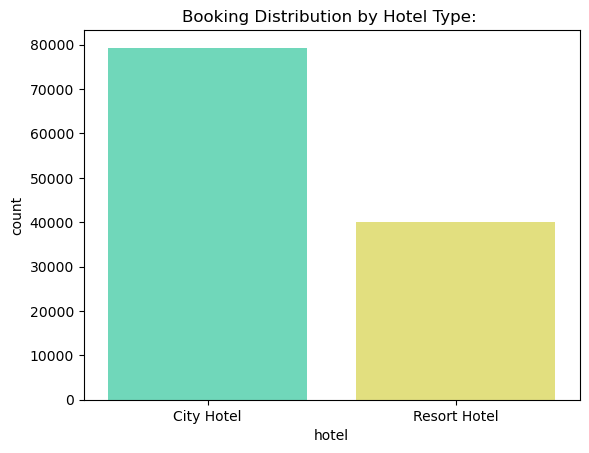

In [15]:
df['hotel'].value_counts()
sns.countplot(x='hotel', data=df,palette=['#5fe8c1','#f2ee6f'])
plt.title("Booking Distribution by Hotel Type: ")
plt.show()

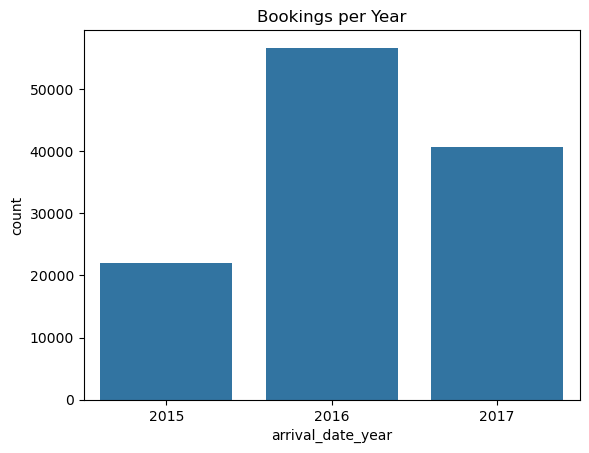

In [3]:
sns.countplot(x='arrival_date_year', data=df)
plt.title("Bookings per Year")
plt.show()

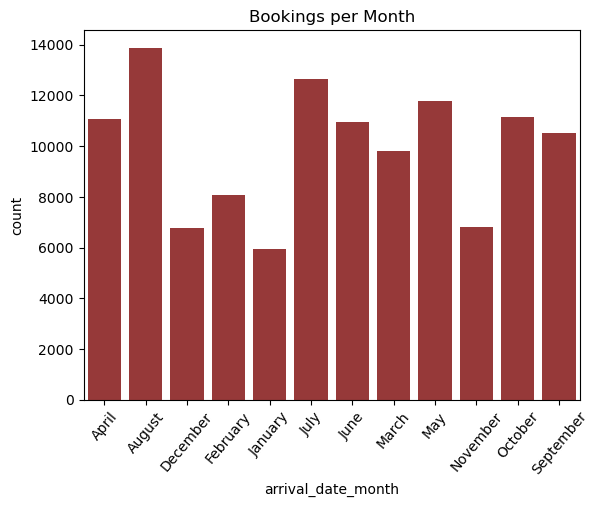

In [4]:
sns.countplot(x='arrival_date_month',data=df,color='brown')
plt.xticks(rotation=50)
plt.title("Bookings per Month")
plt.show()

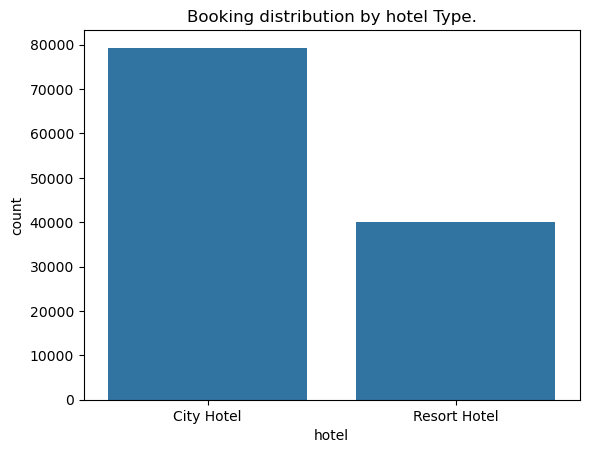

In [5]:
#booking cancelation rate:
df_not_cancelled = df[df['is_canceled'] == 0]
df_not_cancelled['revenue'] = df_not_cancelled['adr'] * df_not_cancelled['total_nights']
#booking distribution by hotel type:
df['hotel'].value_counts()
sns.countplot(x='hotel',data=df)
plt.title('Booking distribution by hotel Type.')
plt.show()

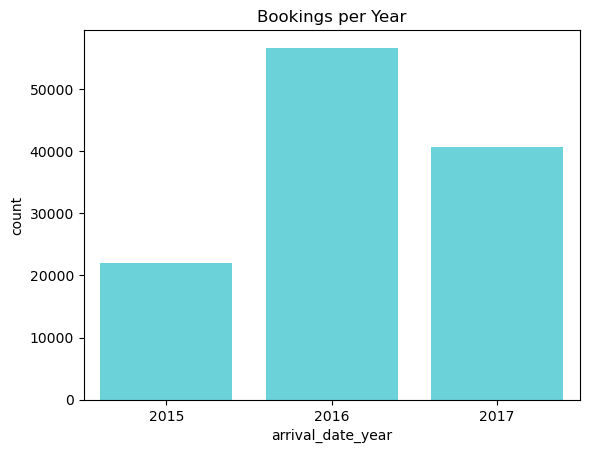

In [12]:
sns.countplot(x='arrival_date_year', data=df, color='#57e3eb')
plt.title("Bookings per Year")
plt.show()

In [1]:
%pip install numpy


Note: you may need to restart the kernel to use updated packages.


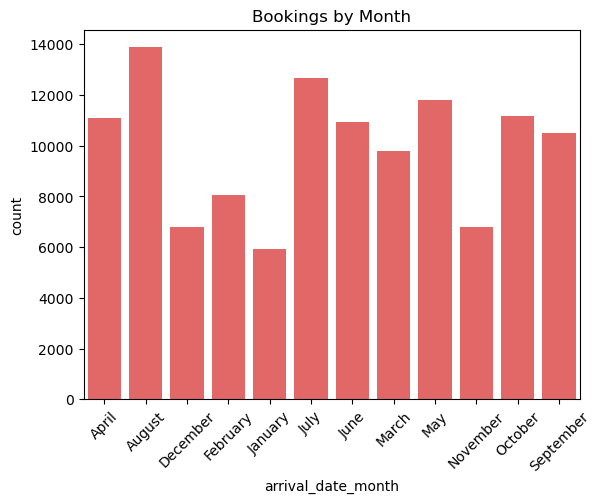

In [13]:
sns.countplot(x='arrival_date_month', data=df, color='#f75252')
plt.xticks(rotation=45)
plt.title("Bookings by Month")
plt.show()

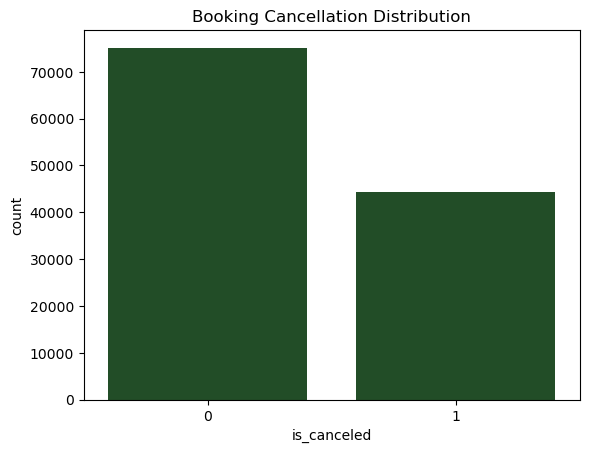

In [16]:
sns.countplot(x='is_canceled', data=df, color='#1b5422')
plt.title("Booking Cancellation Distribution")
plt.show()

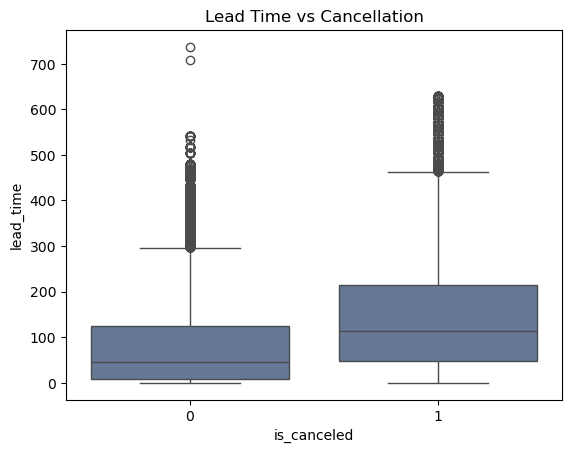

In [19]:
df['is_canceled'].mean()*100
sns.boxplot(x='is_canceled', y='lead_time', data=df, color='#5d769e')
plt.title("Lead Time vs Cancellation")
plt.show()

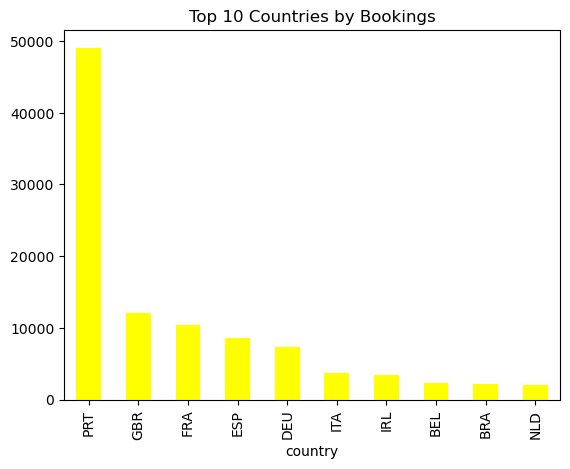

In [29]:
top_countries = df['country'].value_counts().head(10)
top_countries.plot(kind='bar',color='yellow')
plt.title("Top 10 Countries by Bookings")
plt.show()

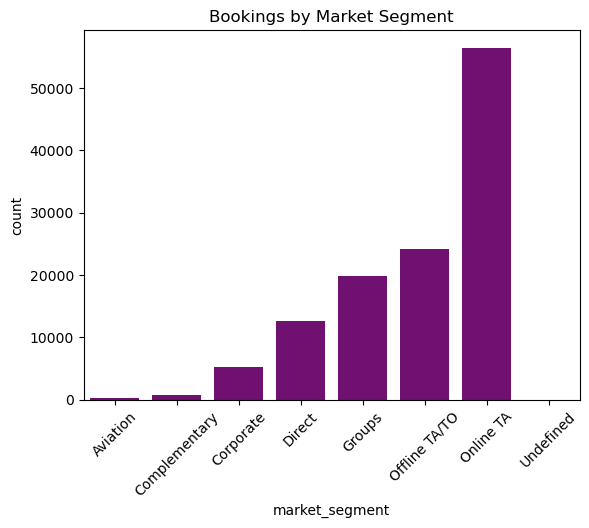

In [31]:
sns.countplot(x='market_segment', data=df, color='purple')
plt.xticks(rotation=45)
plt.title("Bookings by Market Segment")
plt.show()

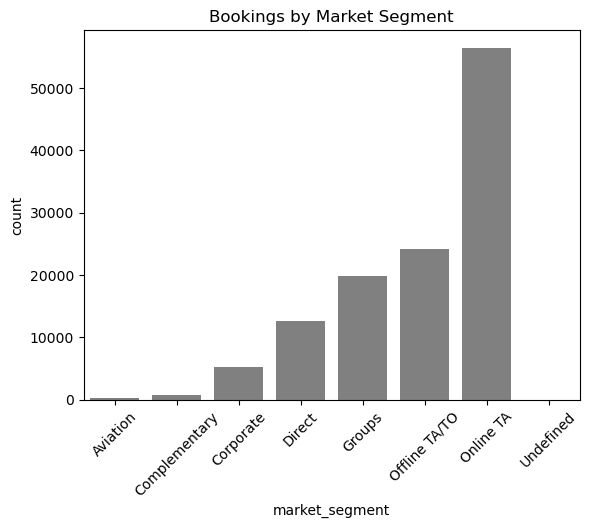

In [32]:
sns.countplot(x='market_segment', data=df, color='gray')
plt.xticks(rotation=45)
plt.title("Bookings by Market Segment")
plt.show()

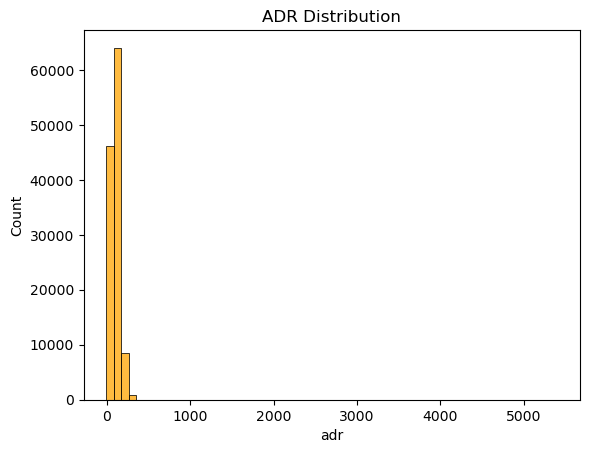

In [36]:
sns.histplot(df['adr'], bins=60,color='orange')
plt.title("ADR Distribution")
plt.show()

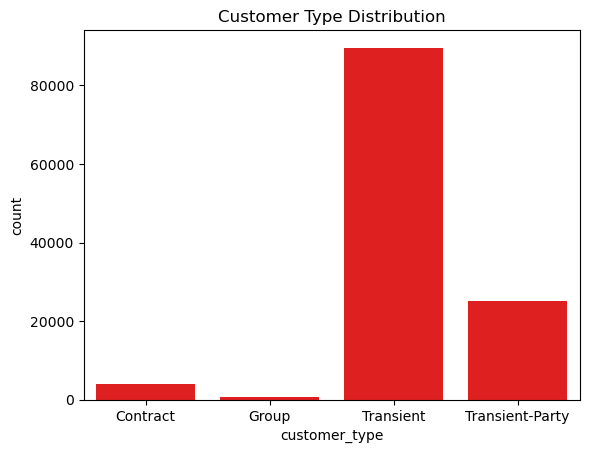

In [37]:
sns.countplot(x='customer_type', data=df, color='red')
plt.title("Customer Type Distribution")
plt.show()

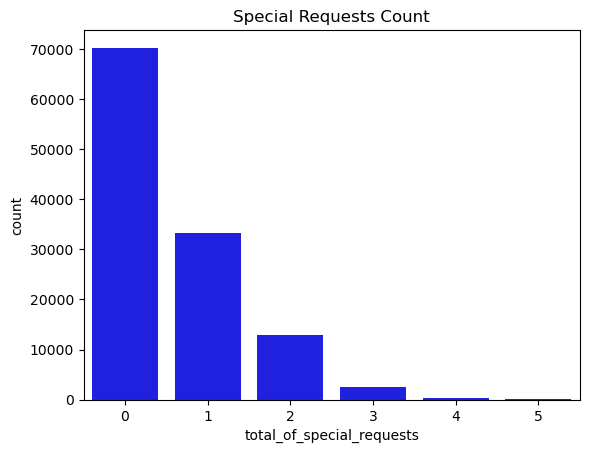

In [38]:
sns.countplot(x='total_of_special_requests', data=df, color='blue')
plt.title("Special Requests Count")
plt.show()